<a href="https://colab.research.google.com/github/rushilnanga/walmart-hurricane-project/blob/main/2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

In [2]:
#Lab 9: cleaning
import os, sqlite3
import pandas as pd
import numpy as np

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')


DB_PATH = 'inventory_and_sales.db'
STORES_PATH = 'store_locations.csv'

# sqlite3.connect() quietly makes an empty database if the file is missing, so check first
assert os.path.exists(DB_PATH), f'{DB_PATH} not found - upload it to the same folder as the notebook'
conn = sqlite3.connect(DB_PATH)

def q(sql):
    return pd.read_sql_query(sql, conn)

sales_raw = q('SELECT * FROM daily_sales_summary')
inventory_raw = q('SELECT * FROM inventory_levels')
stores_raw = pd.read_csv(STORES_PATH)


def drop_duplicates(df):
  'Remove rows that are exact copies of another row'
  out = df.drop_duplicates().reset_index(drop=True)
  log('Drop duplicates', 'Removed exact duplicate rows', len(df) - len(out))
  return out


def clean_numbers(df):
  'Strip $ and commas, then make units and revenue floats'
  out = df.copy()
  affected_rows = 0
  for col in ['total_units', 'total_revenue']:
    affected_rows += out[col].astype(str).str.contains('[$,]', regex=True).sum()
    out[col] = out[col].astype(str).str.replace('[$,]', '', regex=True).astype(float)
  log('Clean numbers', 'Removed $ and commas, changed total_units and total_revenue to float', affected_rows)
  return out


def clean_negatives(df):
  'Negative units, negative revenue, and half units'
  out = df.copy()

  # negative units are returns; keep them so nothing is lost, but flag them
  neg_units = out['total_units'] < 0
  out['neg_units_flag'] = neg_units
  log('Negative units', 'Kept rows with negative total_units and flagged them', neg_units.sum())

  # negative revenue with positive units: can't tell a sign error from a refund, so don't guess
  bad_rev = (out['total_revenue'] < 0) & (out['total_units'] > 0)
  out['revenue_flag'] = bad_rev
  out.loc[bad_rev, 'total_revenue'] = np.nan
  log('Negative revenue', 'Set negative revenue to NaN, kept the units, flagged the row', bad_rev.sum())

  # you can't sell half an item, but rounding either way would be a guess
  half = out['total_units'] % 1 != 0
  out['half_unit_flag'] = half
  log('Half units', 'Kept x.5 unit totals and flagged them', half.sum())
  return out


def parse_dates(df):
  'The date column has two formats: 2024-09-01 and 20240901'
  out = df.copy()
  print(out['date'].str.len().value_counts())  # 10 = YYYY-MM-DD, 8 = YYYYMMDD
  short = out['date'].str.len() == 8
  d = out.loc[short, 'date']
  out.loc[short, 'date'] = d.str[:4] + '-' + d.str[4:6] + '-' + d.str[6:]
  out['date'] = pd.to_datetime(out['date'], format='%Y-%m-%d')
  log('Parse dates', 'Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime', short.sum())
  return out


def clean_store_id(df, name):
  'FL239, FL_287, fl 78 -> FL-239, FL-287, FL-078 (keep the digits, rebuild the id)'
  out = df.copy()
  before = out['store_id'].copy()
  digits = out['store_id'].astype(str).str.replace(r'\D', '', regex=True)
  out['store_id'] = 'FL-' + digits.str.zfill(3)
  log(f'Clean store_id ({name})', 'Rebuilt every store_id as FL-### so the files join', (before != out['store_id']).sum())
  return out


def clean_stores(stores):
  'Store file: fix the ids, remove stores listed twice, fix state, coordinates and timezone'
  out = clean_store_id(stores, 'stores')

  rows_before = len(out)
  out = out.drop_duplicates(subset='store_id').reset_index(drop=True)
  log('Store duplicates', 'Dropped stores listed twice under different ids (FL239, FL_287)', rows_before - len(out))

  STATE_MAP = {'Florida': 'FL', 'Fla.': 'FL'}
  changed = out['state'].isin(STATE_MAP.keys()).sum()
  out['state'] = out['state'].map(STATE_MAP).fillna(out['state'])
  out['region'] = out['region'].str.strip()
  log('Store state', 'Changed Florida and Fla. to FL', changed)

  # Tallahassee has no coordinates and the weather API needs them, so I used the city centre
  missing = out['latitude'].isna().sum()
  out.loc[out['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
  log('Store coordinates', 'Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates', missing)

  # Pensacola is on Central time, every other store is Eastern (needed to line up the weather)
  out['tz'] = np.where(out['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')
  log('Store timezone', 'Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest',
      (out['tz'] == 'America/Chicago').sum())
  return out


def clean_sales(df):
  'Run every sales cleaning step in order'
  out = drop_duplicates(df)
  out = clean_numbers(out)
  out = clean_negatives(out)
  out = parse_dates(out)
  out = clean_store_id(out, 'sales')
  return out


stores = clean_stores(stores_raw)
sales = clean_sales(sales_raw)

print()
print(f'Rows before cleaning: {len(sales_raw)}')
print(f'Rows after cleaning: {len(sales)}')
print(f'Rows removed: {len(sales_raw) - len(sales)}')
print(f'Store file: {len(stores_raw)} rows before, {len(stores)} rows after')
sales.head(10)


[Clean store_id (stores)] Rebuilt every store_id as FL-### so the files join (2 row(s))
[Store duplicates] Dropped stores listed twice under different ids (FL239, FL_287) (2 row(s))
[Store state] Changed Florida and Fla. to FL (3 row(s))
[Store coordinates] Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates (1 row(s))
[Store timezone] Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest (1 row(s))
[Drop duplicates] Removed exact duplicate rows (0 row(s))
[Clean numbers] Removed $ and commas, changed total_units and total_revenue to float (0 row(s))
[Negative units] Kept rows with negative total_units and flagged them (0 row(s))
[Negative revenue] Set negative revenue to NaN, kept the units, flagged the row (34 row(s))
[Half units] Kept x.5 unit totals and flagged them (76 row(s))
date
10    3382
8      218
Name: count, dtype: int64
[Parse dates] Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime (218 row(s))
[Clean s

,date,store_id,category,total_units,total_revenue,neg_units_flag,revenue_flag,half_unit_flag
0,2024-09-12,FL-239,Emergency,90.0,1582.55,False,False,False
1,2024-09-12,FL-239,Breakfast,57.0,356.99,False,False,False
2,2024-09-12,FL-239,Alcohol,41.0,246.65,False,False,False
3,2024-09-12,FL-239,Entertainment,53.0,916.56,False,False,False
4,2024-09-12,FL-239,Grocery,69.0,339.30,False,False,False
5,2024-09-12,FL-239,Electronics,71.5,1011.93,False,False,True
6,2024-09-12,FL-239,Snacks,43.0,493.17,False,False,False
7,2024-09-12,FL-239,Household,24.0,341.84,False,False,False
8,2024-09-12,FL-239,Health,92.0,913.83,False,False,False
9,2024-09-12,FL-239,Baby,52.0,551.50,False,False,False


## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [16]:
# TODO: the numbers
tx = pd.read_csv('/content/walmart_transactions.csv').drop_duplicates()
tx = tx[tx['quantity'] > 0].copy()
tx['date'] = pd.to_datetime(tx['timestamp'], errors='coerce', format='mixed').dt.normalize()

#category labels (18)
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household',
    }

before = tx['category'].nunique()
tx['category'] = tx['category'].str.strip().str.title().replace(CATEGORY_MAP)
log('Category labels', 'Strip, title-case, merge duplicate category names', before-tx['category'].nunique())

#windows: daily volume peaks at Sept 24-25 and drops after Sept 26
BASELINE = ('2024-09-01', '2024-09-15')
SURGE = ('2024-09-19', '2024-09-25')

daily_cat = tx.groupby(['date', 'category'])['quantity'].sum().unstack()

q1 = pd.DataFrame({
    'baseline_avg': daily_cat.loc[BASELINE[0]:BASELINE[1]].mean(),
    'surge_avg': daily_cat.loc[SURGE[0]:SURGE[1]].mean(),
})

q1['multiple'] = q1['surge_avg'] / q1['baseline_avg']
q1 ['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('multiple', ascending=False)

print('Baseline window:', BASELINE[0], 'to' , BASELINE[1])
print('Surge window:', SURGE[0], 'to' , SURGE[1])
print('Rows with no timestamp (not in any window)', tx['date'].isna().sum())
q1.round(2)

[Category labels] Strip, title-case, merge duplicate category names (27 row(s))
Baseline window: 2024-09-01 to 2024-09-15
Surge window: 2024-09-19 to 2024-09-25
Rows with no timestamp (not in any window) 881


,baseline_avg,surge_avg,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94


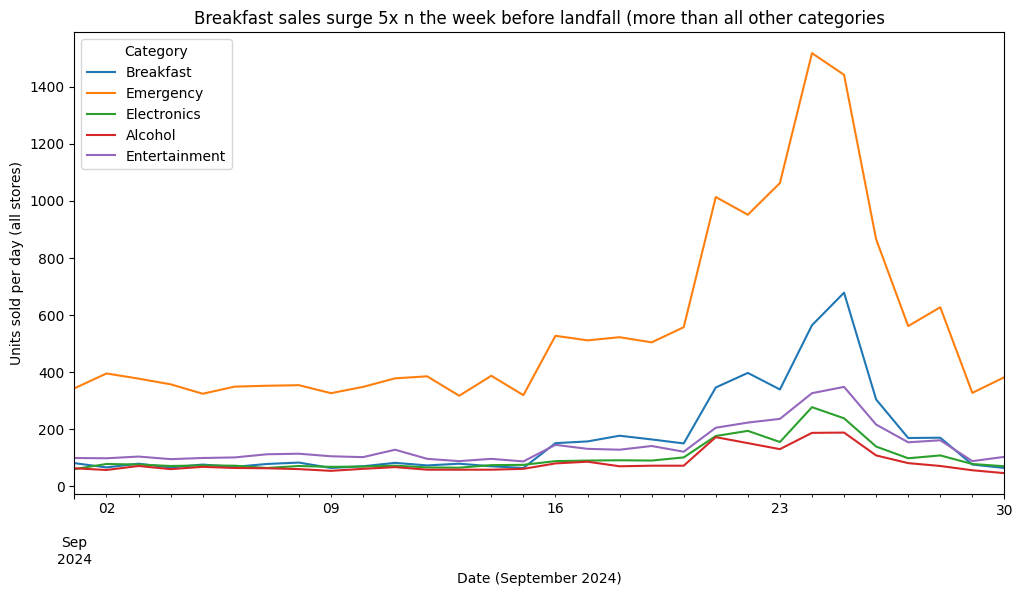

In [19]:
# TODO: the chart
import matplotlib.pyplot as plt
top5 = q1.index[:5]
daily_cat[top5].plot(figsize=(12, 6))
plt.title('Breakfast sales surge 5x the week before landfall (more than all other categories)')
plt.xlabel('Date (September 2024)')
plt.ylabel('Units sold per day (all stores)')
plt.legend(title='Category')
plt.show()

**Q1 answer, in one sentence a manager could read: In the 7 days before landfall (Sept 19-25) vs Sept 1-15, Breakfast sales rose 5.1x and Emergency supplies 2.8x (2 largest surges of the categories)

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [18]:
# TODO
SKU_MAP = {
     'POPTART-STRAW': ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812'],
    'WATER24PK': ['WATER24PK', 'WTR-24', 'WTR_24PK'],
    'BAT-AA4': ['BAT-AA4', 'BATT-100', 'BATT_AA_4PK'],
    'BG-MONO': ['BG-MONO', 'GAME-MONO', 'MONOPOLY-01'],
    'FLASH-01': ['FLASH-01', 'LED-FLASH'], 'BEER-24': ['BEER-24', 'LTBEER24'],
    'CARDS-01': ['CARDS-01', 'PLAYCARD-STD'], 'ROKU-STD': ['ROKU-STD', 'STREAM-01'],
    'CNSOUP-01': ['CNSOUP-01', 'SOUP-CAN'], 'BREAD-WH': ['BREAD-WH', 'WHITEBREAD'],
    'PB-16': ['PB-16', 'PNUTBTR-16'], 'CANDLE-EMRG': ['CANDLE-EMRG', 'CNDL-EM'],
    'FAID-01': ['FAID-01', 'FIRSTAID-KIT'], 'CHRG-PORT': ['CHRG-PORT', 'PORTCHARGER'],
    'CHIPS-VP': ['CHIPS-VP', 'CHIPVARIETY'], 'PAPERTOWEL6': ['PAPERTOWEL6', 'PTOWEL-6'],
    'TOILETPAPER12': ['TOILETPAPER12', 'TP-12'], 'DIAP-S3': ['DIAP-S3', 'DIAPERS-3'],
    'BABYFORMULA': ['BABYFORMULA', 'BFORM-01'], 'HDTARP-01': ['HDTARP-01', 'TARP-HD'],
}

variant_to_canonical = {}
for canonical, variants in SKU_MAP.items():
    for variant in variants:
        variant_to_canonical[variant] = canonical

tx['canonical_sku'] = tx['sku'].map(variant_to_canonical).fillna(tx['sku'])
log('SKU consolidation', 'Mapped variant SKUs to one canonical SKU per product', tx['sku'].nunique()-tx['canonical_sku'].nunique())

assert tx['canonical_sku'].notna().all()
assert tx.groupby('canonical_sku')['quantity'].sum().sum() == tx['quantity'].sum()

sizes = tx.groupby('canonical_sku')['sku'].nunique()
print('Starting SKUs', tx['sku'].nunique())
print('canonical products:', tx['canonical_sku'].nunique())
print('largest family:', sizes.idxmax(), f'({sizes.max()} SKUs)')

#before vs after for Pop-Tarts (q1 window)
daily_sku = tx.groupby(['date', 'sku'])['quantity'].sum().unstack(fill_value=0)
pt = daily_sku[SKU_MAP['POPTART-STRAW']]
cmp = pd.DataFrame({'baseline_avg': pt.loc[BASELINE[0]:BASELINE[1]].mean(),
                    'surge_avg': pt.loc[SURGE[0]:SURGE[1]].mean()})
cmp.loc['All 4 COMBINED'] = [pt.sum(axis=1).loc[BASELINE[0]:BASELINE[1]].mean(),
                        pt.sum(axis=1).loc[SURGE[0]:SURGE[1]].mean()]

cmp.round(1)


[SKU consolidation] Mapped variant SKUs to one canonical SKU per product (25 row(s))
Starting SKUs 45
canonical products: 20
largest family: POPTART-STRAW (4 SKUs)


,baseline_avg,surge_avg
sku,,
POPTART-STRAW,18.0,91.0
PT-12,20.4,103.3
PT_STRAWBERRY,18.1,92.4
SKU#459812,16.8,90.1
All 4 COMBINED,73.3,376.9


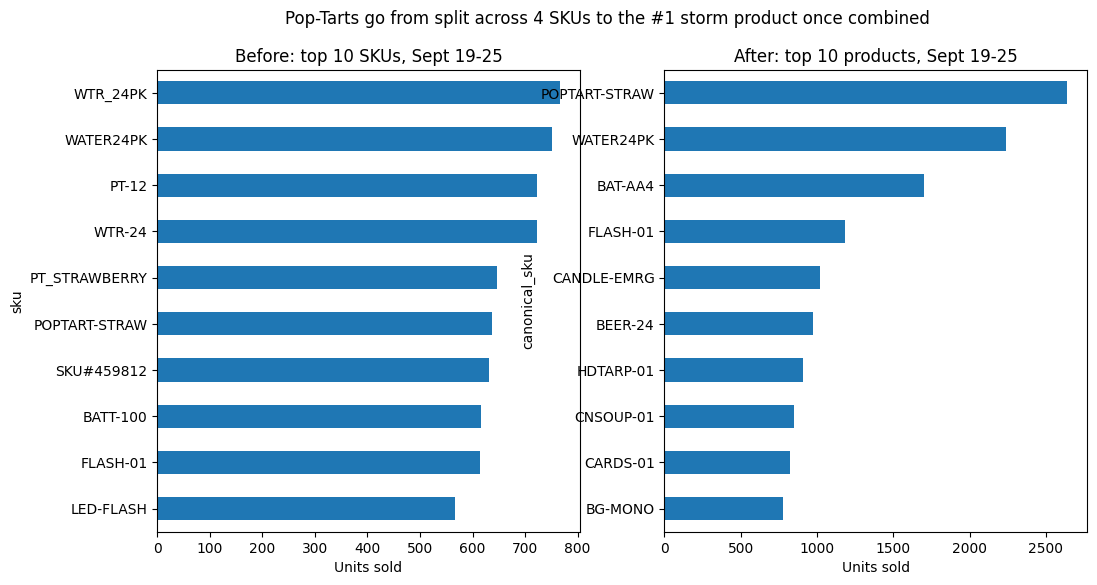

In [27]:
#chart
in_surge = tx['date'].between(*SURGE)
surge_sku = tx[in_surge].groupby('sku')['quantity'].sum().nlargest(10).sort_values()
surge_prod = tx[in_surge].groupby('canonical_sku')['quantity'].sum().nlargest(10).sort_values()

fig, axes = plt.subplots(1,2,figsize=(12,6))
surge_sku.plot.barh(ax=axes[0], title='Before: top 10 SKUs, Sept 19-25')
surge_prod.plot.barh(ax=axes[1], title='After: top 10 products, Sept 19-25')
axes[0].set_xlabel("Units sold")
axes[1].set_xlabel("Units sold")
fig.suptitle('Pop-Tarts go from split across 4 SKUs to the #1 storm product once combined')
plt.show()


**Q2 answer:Combining the 4 Pop-Tart SKUs into one product shows about 377 units/day in the week before landfall (5.1x the Sept 1-15 baseline); it shows it to be the number 1 storm product

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_